In [34]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings 
warnings.filterwarnings("ignore")

In [35]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_PATH = PROJECT_DIR / "data" / "raw_data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)

In [36]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [37]:
df.drop('customerID',axis=1,inplace=True)

In [38]:
def discovering_data(data):
    print("number of rows and columns:", data.shape)
    print("data types of the columns:", data.dtypes)
    # print("checking for nulls :",data.isnull().sum())
    print("numeric columns :",df.select_dtypes(include="int").columns.to_list())
    print("categorical columns :",df.select_dtypes(include="object").columns.to_list())
discovering_data(df) 


number of rows and columns: (7043, 20)
data types of the columns: gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
numeric columns : ['SeniorCitizen', 'tenure']
categorical columns : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [39]:
def checking_nulls_duplicates(data):
    print(f"checking nulls of the colums{df.isnull().sum()}")
    print(f"checking duplicates:{data.duplicated().sum()}")
checking_nulls_duplicates(df)

checking nulls of the columsgender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
checking duplicates:22


In [40]:
categorical_data=df.select_dtypes(include="object").columns.tolist()
for cols in categorical_data:
    print(f"n. of unique values {cols}: {df[cols].nunique()}")



n. of unique values gender: 2
n. of unique values Partner: 2
n. of unique values Dependents: 2
n. of unique values PhoneService: 2
n. of unique values MultipleLines: 3
n. of unique values InternetService: 3
n. of unique values OnlineSecurity: 3
n. of unique values OnlineBackup: 3
n. of unique values DeviceProtection: 3
n. of unique values TechSupport: 3
n. of unique values StreamingTV: 3
n. of unique values StreamingMovies: 3
n. of unique values Contract: 3
n. of unique values PaperlessBilling: 2
n. of unique values PaymentMethod: 4
n. of unique values TotalCharges: 6531
n. of unique values Churn: 2


In [41]:
df["MonthlyCharges"].apply(lambda x: isinstance(x, str)).sum()
#method for detecting if the column has any strings in a numeric column

np.int64(0)

In [42]:
SchemeColumn={
    'gender':str,
    'SeniorCitizen':int,
    'Partner':str,
    'Dependents':str,
    'tenure':int,
    'PhoneService':str,
    'MultipleLines':str,
    'InternetService':str,
    'OnlineSecurity':str,
     'OnlineBackup':str,
     'DeviceProtection':str,
     'TechSupport':str,
     'StreamingTV':str,
     'StreamingMovies':str,
     'Contract':str,
     'PaperlessBilling':str,
     'PaymentMethod':str,
     'MonthlyCharges':float,
     'TotalCharges':float,
     'Churn':str
}

for column, expected_dtype in SchemeColumn.items():
    if df[column].dtype != expected_dtype:
        print(f"{column}: expected {expected_dtype}, got {df[column].dtype}")

gender: expected <class 'str'>, got object
Partner: expected <class 'str'>, got object
Dependents: expected <class 'str'>, got object
PhoneService: expected <class 'str'>, got object
MultipleLines: expected <class 'str'>, got object
InternetService: expected <class 'str'>, got object
OnlineSecurity: expected <class 'str'>, got object
OnlineBackup: expected <class 'str'>, got object
DeviceProtection: expected <class 'str'>, got object
TechSupport: expected <class 'str'>, got object
StreamingTV: expected <class 'str'>, got object
StreamingMovies: expected <class 'str'>, got object
Contract: expected <class 'str'>, got object
PaperlessBilling: expected <class 'str'>, got object
PaymentMethod: expected <class 'str'>, got object
TotalCharges: expected <class 'float'>, got object
Churn: expected <class 'str'>, got object


In [43]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"], errors="coerce")

In [44]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [45]:
df.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Distribution of MonthlyCharges: mean=64.76169246059918, median=70.35, std=30.090047097678493


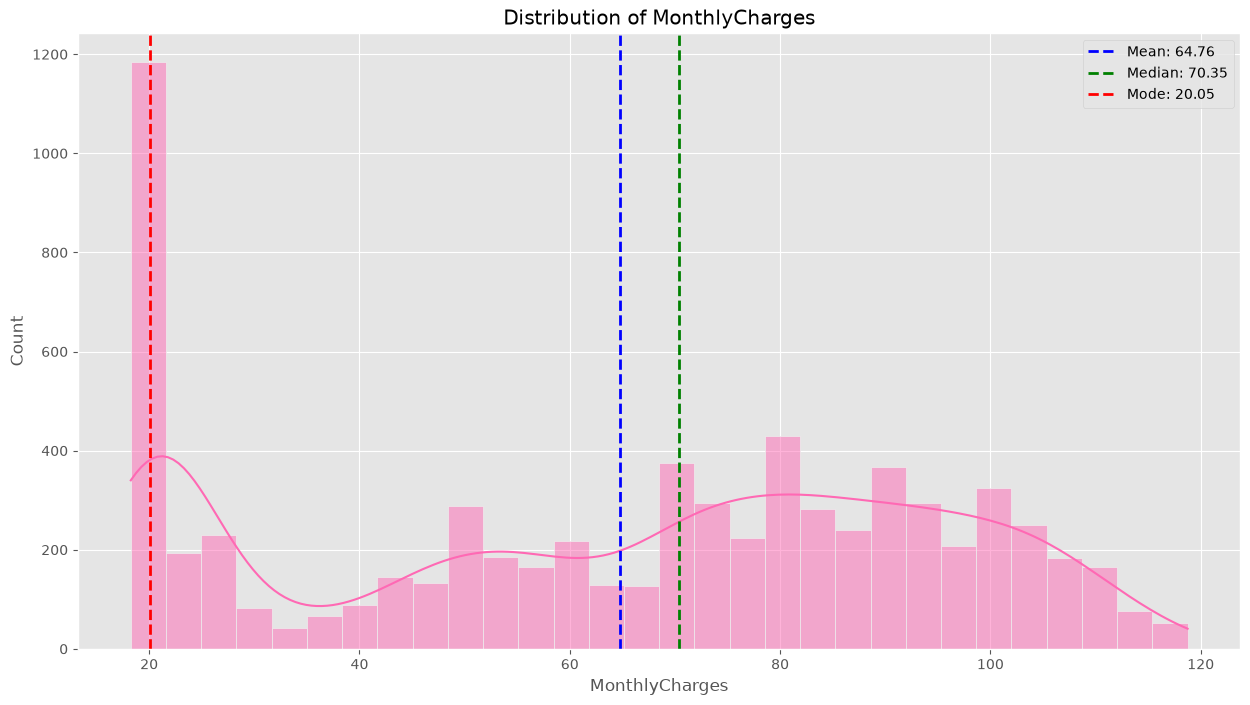

Distribution of TotalCharges: mean=2283.3004408418656, median=1397.475, std=2266.771361883145


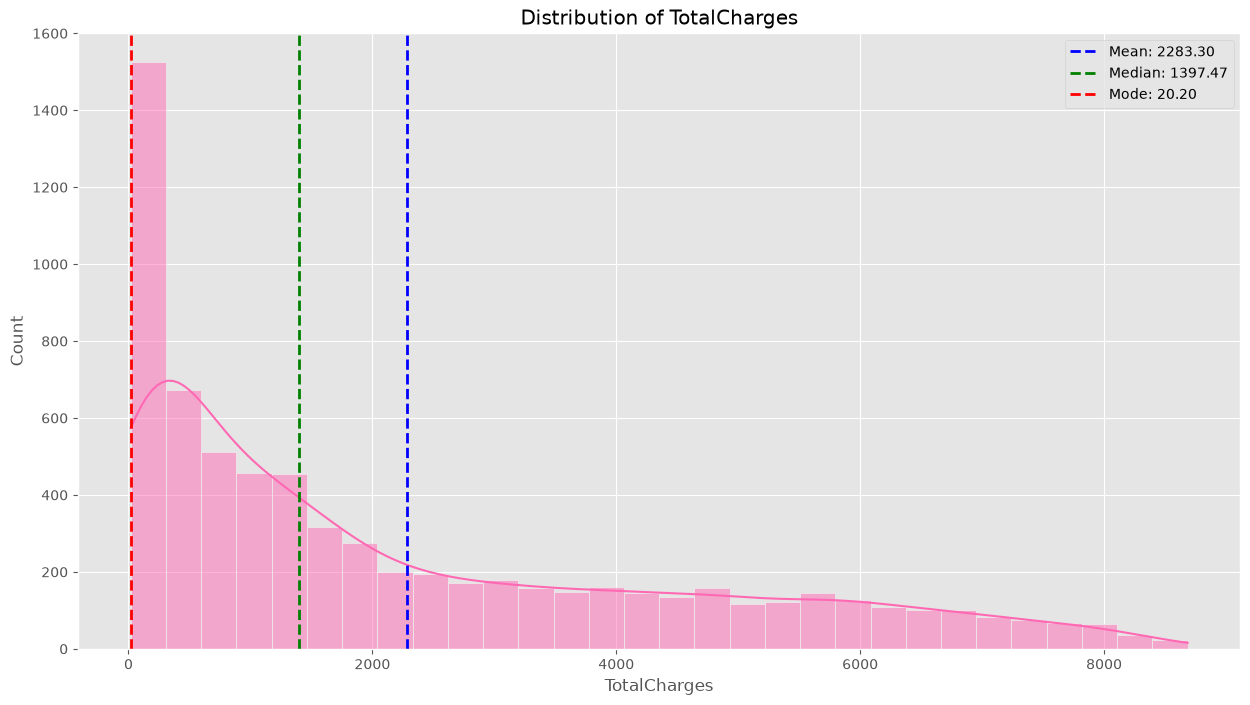

In [46]:
# checking the distribution of the data 
plt.style.use("ggplot")
def distribution(data,col):
    mean=data[col].mean()
    median=data[col].median()
    std=data[col].std()
    mode=data[col].mode()[0]
    print(f"Distribution of {col}: mean={mean}, median={median}, std={std}")
    plt.figure(figsize=(15,8))
    sns.histplot(data[col], kde=True, bins=30,color="hotpink")
    plt.title(f"Distribution of {col}")
    plt.axvline(mean, color='blue', linestyle='dashed', linewidth=2, label=f'Mean: {mean:.2f}')
    plt.axvline(median, color='green', linestyle='dashed', linewidth=2, label=f'Median: {median:.2f}')
    plt.axvline(mode, color='red', linestyle='dashed', linewidth=2, label=f'Mode: {mode:.2f}')
    plt.xlabel(col)
    plt.legend()
    plt.show()
   
for col in df.select_dtypes(include="float").columns:
    distribution(df,col)

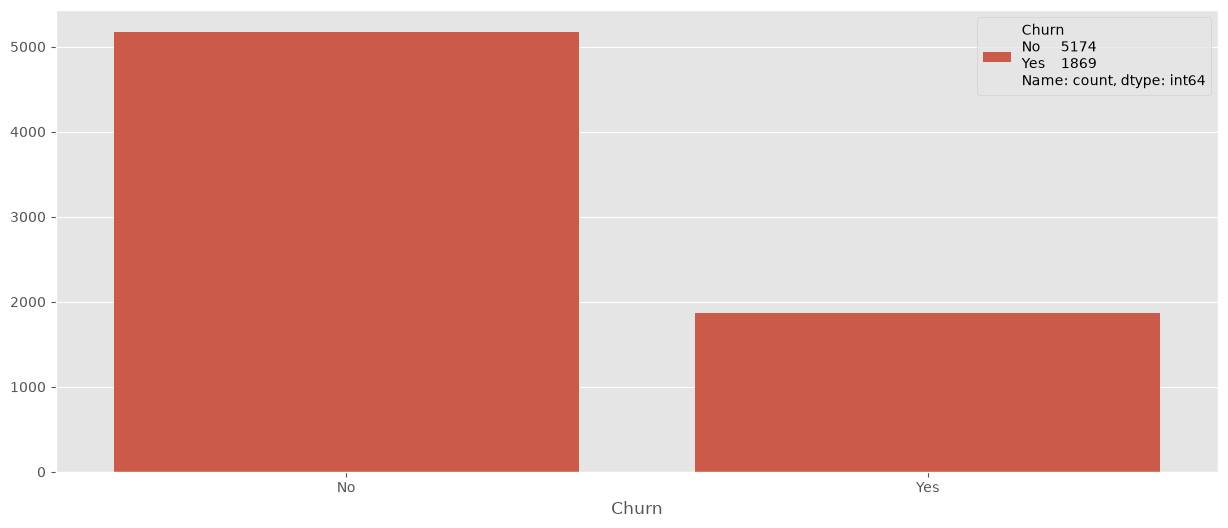

In [47]:
# data balance
categories=df["Churn"].value_counts()
plt.figure(figsize=(15,6))
sns.barplot(x=categories.index,y=categories.values,label=f"{categories}")
plt.legend()
plt.show()

In [51]:
df.select_dtypes(include="float").describe()

,MonthlyCharges,TotalCharges
count,7043.000000,7032.000000
mean,64.761692,2283.300441
std,30.090047,2266.771362
min,18.250000,18.800000
25%,35.500000,401.450000
50%,70.350000,1397.475000
75%,89.850000,3794.737500
max,118.750000,8684.800000



Column: MonthlyCharges
Skewness: -0.22
Excess kurtosis: -1.26
Shapiro statistic: 0.9209
P-value: 2.23e-51
Shapiro-Wilk test
Evidence against normality (reject H0)


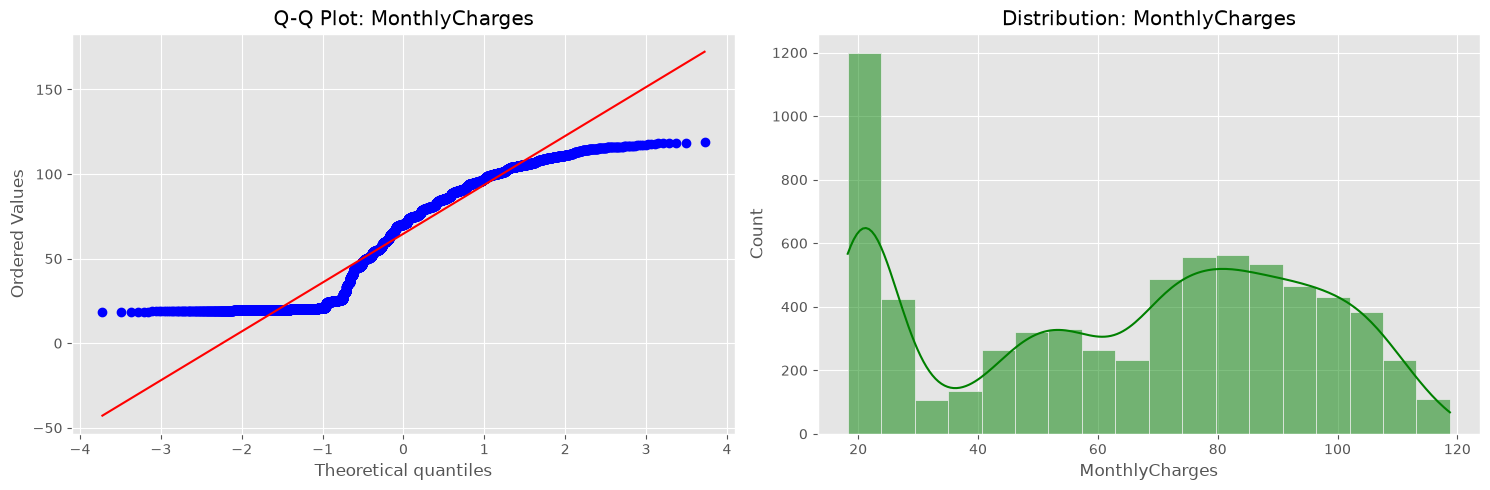


Column: TotalCharges
Skewness: 0.96
Excess kurtosis: -0.23
Shapiro statistic: 0.8604
P-value: 1.051e-61
Shapiro-Wilk test
Evidence against normality (reject H0)


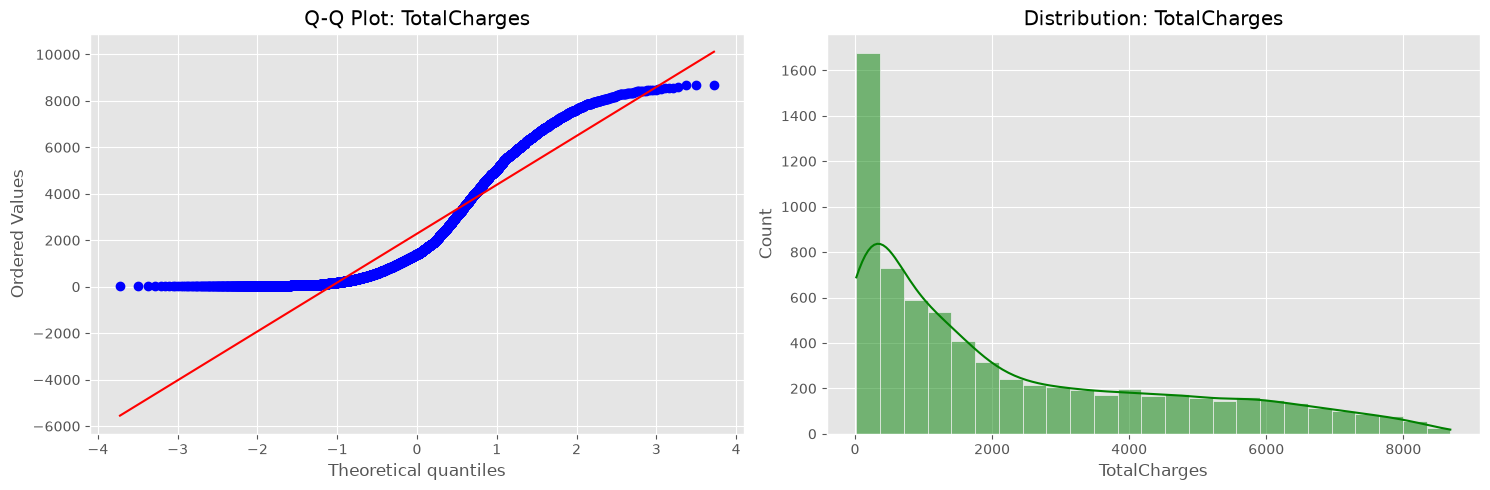

In [56]:

from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

for col in df.select_dtypes(include=["float"]).columns:
    values = df[col].dropna()
    skewness = values.skew()
    kurtosis = values.kurt()
    stat, p_value = stats.shapiro(values)
    print(f"\nColumn: {col}")
    print(f"Skewness: {skewness:.2f}")
    print(f"Excess kurtosis: {kurtosis:.2f}")
    print(f"Shapiro statistic: {stat:.4f}")
    print(f"P-value: {p_value:.4g}")
    print("Shapiro-Wilk test")
    if p_value < 0.05:
        print("Evidence against normality (reject H0)")
    else:
        print("Insufficient evidence to reject normality")
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 2, 1)
    stats.probplot(values, dist="norm", plot=plt)
    plt.title(f"Q-Q Plot: {col}")
    plt.subplot(1, 2, 2)
    sns.histplot(values, color="green", kde=True)
    plt.title(f"Distribution: {col}")
    plt.tight_layout()
    plt.show()
